# Explore the competitive-runners dataset

Goal: understand the data's shape, find the injury rate, and generate `data/README.md`.

Put the Kaggle CSVs in `data/raw/` first. Start with the **day approach** file.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

PATH = "data/raw/day_approach_maskedID_timeseries.csv"
df = pd.read_csv(PATH)

print(df.shape)
df.head()

(42766, 73)


,nr. sessions,total km,km Z3-4,km Z5-T1-T2,km sprinting,strength training,hours alternative,perceived exertion,perceived trainingSuccess,perceived recovery,...,km Z5-T1-T2.6,km sprinting.6,strength training.6,hours alternative.6,perceived exertion.6,perceived trainingSuccess.6,perceived recovery.6,Athlete ID,injury,Date
0,1.0,5.8,0.0,0.6,1.2,0.0,0.00,0.11,0.00,0.18,...,0.0,0.0,0.0,1.0,0.10,0.00,0.15,0,0,0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.00,-0.01,-0.01,-0.01,...,0.5,1.2,0.0,0.0,0.10,0.00,0.17,0,0,1
2,1.0,0.0,0.0,0.0,0.0,1.0,0.00,0.10,0.00,0.17,...,0.0,0.0,0.0,0.0,-0.01,-0.01,-0.01,0,0,2
3,0.0,0.0,0.0,0.0,0.0,0.0,0.00,-0.01,-0.01,-0.01,...,0.0,0.0,1.0,0.0,0.10,0.00,0.17,0,0,3
4,1.0,0.0,0.0,0.0,0.0,0.0,1.08,0.08,0.00,0.18,...,0.0,0.0,0.0,0.0,0.11,0.00,0.17,0,0,4


## 1. Look at the columns

The day file has one row per athlete-day, with the previous 7 days of training spread across columns (suffixes `.1`, `.2`, ...). Find the athlete ID, date and injury columns in this list and set them below.

In [2]:
pd.set_option("display.max_rows", 100)
print(list(df.columns))
df.dtypes.value_counts()

['nr. sessions', 'total km', 'km Z3-4', 'km Z5-T1-T2', 'km sprinting', 'strength training', 'hours alternative', 'perceived exertion', 'perceived trainingSuccess', 'perceived recovery', 'nr. sessions.1', 'total km.1', 'km Z3-4.1', 'km Z5-T1-T2.1', 'km sprinting.1', 'strength training.1', 'hours alternative.1', 'perceived exertion.1', 'perceived trainingSuccess.1', 'perceived recovery.1', 'nr. sessions.2', 'total km.2', 'km Z3-4.2', 'km Z5-T1-T2.2', 'km sprinting.2', 'strength training.2', 'hours alternative.2', 'perceived exertion.2', 'perceived trainingSuccess.2', 'perceived recovery.2', 'nr. sessions.3', 'total km.3', 'km Z3-4.3', 'km Z5-T1-T2.3', 'km sprinting.3', 'strength training.3', 'hours alternative.3', 'perceived exertion.3', 'perceived trainingSuccess.3', 'perceived recovery.3', 'nr. sessions.4', 'total km.4', 'km Z3-4.4', 'km Z5-T1-T2.4', 'km sprinting.4', 'strength training.4', 'hours alternative.4', 'perceived exertion.4', 'perceived trainingSuccess.4', 'perceived recover

float64    70
int64       3
Name: count, dtype: int64

In [4]:
# Set these from the column list above
ID = "Athlete ID"
DATE = "Date"
INJ = "injury"

assert {ID, DATE, INJ} <= set(df.columns), "Fix the column names above"
print(df[INJ].value_counts(dropna=False))

print("Missing values in total:", df.isna().sum().sum())

injury
0    42183
1      583
Name: count, dtype: int64
Missing values in total: 0


## 2. Basic facts: athletes, date range, rows

In [5]:
n_rows, n_cols = df.shape
n_athletes = df[ID].nunique()
date_min, date_max = df[DATE].min(), df[DATE].max()

print(f"Rows: {n_rows:,}  Columns: {n_cols}")
print(f"Athletes: {n_athletes}")
print(f"Date range: {date_min} to {date_max}  (dates may be day indexes, not calendar dates)")

Rows: 42,766  Columns: 73
Athletes: 74
Date range: 0 to 2673  (dates may be day indexes, not calendar dates)


## 3. Count injuries

Two different counts matter:

- **Injury days**: rows where `injury == 1`.
- **Injury onsets**: the first day of each injury. If an injury is flagged on several consecutive days, it is still one event.

Onsets are what you'll model later, so check whether the two numbers differ.

In [6]:
df = df.sort_values([ID, DATE]).reset_index(drop=True)

prev = df.groupby(ID)[INJ].shift(fill_value=0)
df["injury_onset"] = (df[INJ] == 1) & (prev == 0)

injury_days = int(df[INJ].sum())
injury_onsets = int(df["injury_onset"].sum())
overall_rate = df[INJ].mean()

print(f"Injury days: {injury_days}")
print(f"Injury onsets: {injury_onsets}")
print(f"Overall injury rate: {overall_rate:.2%} of rows")

Injury days: 583
Injury onsets: 393
Overall injury rate: 1.36% of rows


In [7]:
per_athlete = df.groupby(ID).agg(
    days=(DATE, "count"),
    first_day=(DATE, "min"),
    last_day=(DATE, "max"),
    injury_days=(INJ, "sum"),
    injury_onsets=("injury_onset", "sum"),
)
per_athlete["onsets_per_1000_days"] = per_athlete["injury_onsets"] / per_athlete["days"] * 1000

never_injured = int((per_athlete["injury_onsets"] == 0).sum())
print(f"Athletes never injured: {never_injured} of {n_athletes}")
per_athlete.sort_values("injury_onsets", ascending=False).head(15)

Athletes never injured: 11 of 74


,days,first_day,last_day,injury_days,injury_onsets,onsets_per_1000_days
Athlete ID,,,,,,
42,744,276,2665,32,22,29.569892
23,1393,0,2642,24,20,14.357502
27,1344,0,2652,22,19,14.136905
9,1233,0,2651,23,18,14.598540
26,884,0,2642,35,17,19.230769
41,1393,277,2649,18,14,10.050251
29,730,0,2651,33,14,19.178082
38,843,276,2403,18,13,15.421115
22,1478,0,2634,21,13,8.795670


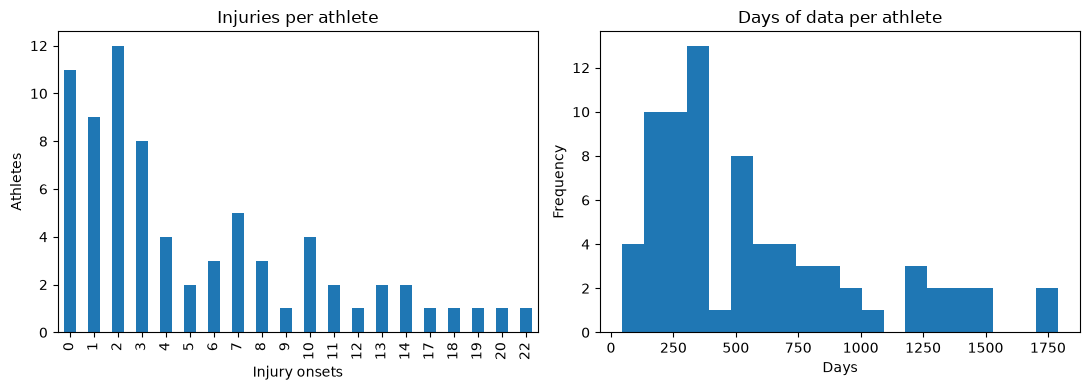

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
per_athlete["injury_onsets"].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set(title="Injuries per athlete", xlabel="Injury onsets", ylabel="Athletes")
per_athlete["days"].plot.hist(bins=20, ax=axes[1])
axes[1].set(title="Days of data per athlete", xlabel="Days")
plt.tight_layout()

## 4. Write the data README

Fill in `INJURY_DEFINITION` and `SOURCE` from the Lovdal paper's methods section and the Kaggle page, then run this cell.

In [9]:
from pathlib import Path

INJURY_DEFINITION = "TODO: copy the definition from the paper's methods section"
SOURCE = "TODO: Kaggle URL and the paper citation"

column_list = "\n".join(f"- `{c}`" for c in df.columns if c != "injury_onset")

readme = f"""# Data: competitive runners injury dataset

**Source:** {SOURCE}
**File:** `{PATH}`

## Summary

| Fact | Value |
| --- | --- |
| Rows | {n_rows:,} (one per athlete-day) |
| Columns | {n_cols} |
| Athletes | {n_athletes} |
| Date range | {date_min} to {date_max} |
| Injury days | {injury_days} |
| Injury onsets | {injury_onsets} |
| Overall injury rate | {overall_rate:.2%} of rows |
| Athletes never injured | {never_injured} |

## Injury definition

{INJURY_DEFINITION}

## Key columns

- `{ID}`: masked athlete identifier
- `{DATE}`: day index
- `{INJ}`: 1 if an injury is recorded that day

## All columns

{column_list}
"""

Path("data").mkdir(exist_ok=True)
Path("data/README.md").write_text(readme)
print(readme)

# Data: competitive runners injury dataset

**Source:** TODO: Kaggle URL and the paper citation
**File:** `data/raw/day_approach_maskedID_timeseries.csv`

## Summary

| Fact | Value |
| --- | --- |
| Rows | 42,766 (one per athlete-day) |
| Columns | 73 |
| Athletes | 74 |
| Date range | 0 to 2673 |
| Injury days | 583 |
| Injury onsets | 393 |
| Overall injury rate | 1.36% of rows |
| Athletes never injured | 11 |

## Injury definition

TODO: copy the definition from the paper's methods section

## Key columns

- `Athlete ID`: masked athlete identifier
- `Date`: day index
- `injury`: 1 if an injury is recorded that day

## All columns

- `nr. sessions`
- `total km`
- `km Z3-4`
- `km Z5-T1-T2`
- `km sprinting`
- `strength training`
- `hours alternative`
- `perceived exertion`
- `perceived trainingSuccess`
- `perceived recovery`
- `nr. sessions.1`
- `total km.1`
- `km Z3-4.1`
- `km Z5-T1-T2.1`
- `km sprinting.1`
- `strength training.1`
- `hours alternative.1`
- `perceived exertion.1`
- `